# DATA 266 Lab 2 — Part 2: Fine-tuning Stable Diffusion 1.5 — LoRA r=4 vs LoRA r=32 (Team 12)

One notebook, one Kaggle run (~50-60 min on a single T4): data preparation → two LoRA runs with the same data,
steps and seed → push both adapters to Hugging Face → 120 images (20 prompts × 2 seeds × 3 models) → KID / CLIP /
LPIPS / efficiency → blinded human-eval pairs → failure modes → memorisation check → model card.

**Speed choices (to fit the Kaggle time budget):** VAE latents and CLIP text embeddings of the training set are
computed once and shared by both runs; no gradient checkpointing (falls back to it automatically if memory runs out);
400 optimiser steps per run at batch 4 (the loss is already flat by ~300 steps); both seeds generated in one call.

**Kaggle:** GPU T4 (only GPU 0 is used), Internet On, secret `HF_TOKEN` (write token).

In [1]:
# Cell 1 - run information (required)
import subprocess, sys, random, numpy as np, torch
SEED = 266; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True,
text=True).stdout.strip()
print({"commit": commit, "python": sys.version.split()[0], "torch": torch.__version__,
       "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", "seed": SEED})

{'commit': '', 'python': '3.13.16', 'torch': '2.11.0+cu130', 'gpu': 'Tesla T4', 'seed': 266}


In [2]:
import importlib, importlib.util, importlib.metadata as _md
def ensure(mod_to_pkg):
    """Install only missing packages, pinning Kaggle's core stack so nothing gets downgraded."""
    missing = [p for m, p in mod_to_pkg.items() if importlib.util.find_spec(m) is None]
    if not missing: return
    keep = []
    for k in ("torch", "torchvision", "transformers", "tokenizers", "huggingface-hub", "numpy", "pillow"):
        try: keep.append(f"{k}=={_md.version(k)}")
        except Exception: pass
    open("/tmp/c.txt", "w").write("\n".join(keep)); print("installing", missing)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-c", "/tmp/c.txt", *missing], check=False)
ensure({"torchmetrics": "torchmetrics", "torch_fidelity": "torch-fidelity", "diffusers": "diffusers", "peft": "peft"})

import os, json, time, glob, hashlib, gc, shutil, traceback
import pandas as pd, matplotlib.pyplot as plt
from PIL import Image, ImageOps
import torch.nn.functional as F, random
import transformers, datasets, torchmetrics
from datasets import load_dataset
from huggingface_hub import HfApi, login, create_repo, snapshot_download
print({"transformers": transformers.__version__, "datasets": datasets.__version__, "torchmetrics": torchmetrics.__version__})

def step(name):
    """Run a section; print the error instead of stopping the whole notebook."""
    def deco(fn):
        t0 = time.time()
        try:
            out = fn(); print(f"[ok] {name} ({time.time()-t0:.0f}s)"); return out
        except Exception as e:
            print(f"[FAILED] {name}: {type(e).__name__}: {e}"); traceback.print_exc(limit=3); return None
    return deco

installing ['torch-fidelity']
{'transformers': '5.20.2', 'datasets': '4.8.5', 'torchmetrics': '1.9.0'}


In [3]:
DATASET = "lambdalabs/naruto-blip-captions"
BASE = "stable-diffusion-v1-5/stable-diffusion-v1-5"
RES = 512
STEPS, BATCH, GRAD_ACC, LR = int(os.environ.get("STEPS", 400)), 4, 1, 1e-4   # identical budget for both runs
RUNS = [{"name": "lora-r4", "rank": 4}, {"name": "lora-r32", "rank": 32}]
MODELS = ["base"] + [r["name"] for r in RUNS]
GEN = dict(num_inference_steps=30, guidance_scale=7.5, height=RES, width=RES)
HF_USER = os.environ.get("HF_USER", "sayani0706")
TEAM = os.environ.get("TEAM", "12")
WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else "outputs/p2"
for d in ("lora", "images", "grids", "human_eval"): os.makedirs(f"{WORK}/{d}", exist_ok=True)
DEVICE = "cuda"

HF_TOKEN = os.environ.get("HF_TOKEN")
try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = HF_TOKEN or UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    pass
if HF_TOKEN: login(HF_TOKEN)
api = HfApi(token=HF_TOKEN)
def repo(kind, team=TEAM): return f"{HF_USER}/data266-lab2-team{team}-p2-{kind}"
def exists(rid, repo_type="model"):
    try: api.repo_info(rid, repo_type=repo_type); return True
    except Exception: return False
print("HF user:", HF_USER, "| team:", TEAM)

HF user: sayani0706 | team: 12


## 2.1 Data preparation — corrupted/duplicate removal, 90/10 split (seed 266), 512×512

In [4]:
raw = load_dataset(DATASET, split="train")
def ahash(img, n=8):
    g = np.asarray(img.convert("L").resize((n, n), Image.BILINEAR), dtype=np.float32)
    return "".join("1" if v else "0" for v in (g > g.mean()).ravel())
kept, n_corrupt, n_exact, n_near, seen_md5, seen_ah = [], 0, 0, 0, set(), set()
for ex in raw:
    try:
        img = ex["image"]; img.load(); img = img.convert("RGB")
        if min(img.size) < 64 or not str(ex.get("text", "")).strip(): raise ValueError
    except Exception:
        n_corrupt += 1; continue
    md5 = hashlib.md5(img.tobytes()).hexdigest()
    if md5 in seen_md5: n_exact += 1; continue
    ah = ahash(img)
    if ah in seen_ah: n_near += 1; continue
    seen_md5.add(md5); seen_ah.add(ah); kept.append({"image": img, "text": ex["text"].strip()})
perm = np.random.RandomState(SEED).permutation(len(kept)); n_test = int(round(0.10 * len(kept)))
fit = lambda im, r=RES: ImageOps.fit(im, (r, r), Image.BICUBIC)
test = [{"image": fit(kept[j]["image"]), "text": kept[j]["text"]} for j in perm[:n_test]]
train512 = [fit(kept[j]["image"]) for j in perm[n_test:]]
train = [{"image": im.resize((256, 256), Image.BICUBIC), "text": kept[j]["text"]} for im, j in zip(train512, perm[n_test:])]   # 256px copies for the memorisation check
cap = pd.Series([len(r["text"].split()) for r in kept])
print(f"original {len(raw)} | corrupted {n_corrupt} | exact dup {n_exact} | near dup {n_near} | kept {len(kept)} | train {len(train)} | test {len(test)}")
print(f"caption words: mean {cap.mean():.1f}, min {cap.min()}, max {cap.max()}")
print("most common caption openings:", pd.Series([" ".join(r['text'].split()[:3]) for r in kept]).value_counts().head(6).to_dict())
del raw; gc.collect()

README.md:   0%|          | 0.00/1.02k [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


dataset_infos.json:   0%|          | 0.00/897 [00:00<?, ?B/s]

data/train-00000-of-00002-12944970063701(…): reconstructing file:   0%|          |  0.00B /  344MB            

data/train-00000-of-00002-12944970063701(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-cefa2f480689f1(…): reconstructing file:   0%|          |  0.00B /  357MB            

data/train-00001-of-00002-cefa2f480689f1(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1221 [00:00<?, ? examples/s]

original 1221 | corrupted 0 | exact dup 0 | near dup 0 | kept 1221 | train 1099 | test 122
caption words: mean 8.9, min 6, max 41
most common caption openings: {'a man with': 406, 'a man in': 212, 'a woman with': 119, 'a person with': 56, 'a girl with': 54, 'an anime character': 43}


150

### Fixed prompt set (committed to Git as `eval/p2_prompts.json` before training finished)

In [5]:
PROMPTS_PATH = next((p for p in ["eval/p2_prompts.json", "../eval/p2_prompts.json", *glob.glob("/kaggle/input/**/p2_prompts.json", recursive=True)] if os.path.exists(p)), None)
if PROMPTS_PATH:
    PROMPTS = json.load(open(PROMPTS_PATH))
else:
    rng = np.random.RandomState(SEED)
    ind = [test[k]["text"] for k in rng.choice(len(test), 10, replace=False)]
    ood = ["a photo of a red sports car parked on a city street at night", "a bowl of ramen on a wooden table, studio food photography",
           "a snowy mountain landscape with a frozen lake at sunrise", "an astronaut riding a horse on the moon",
           "a cozy library with tall bookshelves and warm lamps"]
    cmp = ["two ninja characters, one in red and one in blue, standing side by side",
           "a girl with pink hair holding a white cat next to a boy with black hair",
           "three characters sitting at a table, the one on the left is laughing",
           "a man with a green vest standing behind a small orange fox",
           "a ninja on a rooftop under a full moon with a red scarf blowing in the wind"]
    PROMPTS = ([{"id": f"in{i:02d}", "type": "in_domain", "prompt": p} for i, p in enumerate(ind)] +
               [{"id": f"ood{i:02d}", "type": "out_of_domain", "prompt": p} for i, p in enumerate(ood)] +
               [{"id": f"cmp{i:02d}", "type": "compositional", "prompt": p} for i, p in enumerate(cmp)])
json.dump(PROMPTS, open(f"{WORK}/p2_prompts.json", "w"), indent=1)
pd.DataFrame(PROMPTS)

,id,type,prompt
0,in00,in_domain,a man with a sword in his hand
1,in01,in_domain,a woman in a green and white outfit
2,in02,in_domain,a person with white hair and blue eyes
3,in03,in_domain,a woman with long black hair wearing a blue robe
4,in04,in_domain,a man with a hat and glasses on
5,in05,in_domain,a man with black hair and a brown vest
6,in06,in_domain,a man and a horse in front of a large ball
7,in07,in_domain,a woman in a kimono kimono
8,in08,in_domain,the head of a man with a goat on it's back
9,in09,in_domain,a woman with glasses and a red shirt


## 2.2 Fine-tuning — two runs, same data, same 400-step budget, same seed

tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

text_encoder/model.safetensors: reconstructing file:   0%|          |  0.00B /  492MB            

... (9 outputs left out)

unet/diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

[lora-r4] step 50/400 loss 0.0832 46s
[lora-r4] step 100/400 loss 0.0899 91s
[lora-r4] step 150/400 loss 0.0962 136s
[lora-r4] step 200/400 loss 0.0912 181s
[lora-r4] step 250/400 loss 0.0953 226s
[lora-r4] step 300/400 loss 0.0826 271s
[lora-r4] step 350/400 loss 0.0948 315s
[lora-r4] step 400/400 loss 0.0871 360s
[lora-r32] step 50/400 loss 0.0832 45s
[lora-r32] step 100/400 loss 0.0898 90s
[lora-r32] step 150/400 loss 0.0961 134s
[lora-r32] step 200/400 loss 0.0911 179s
[lora-r32] step 250/400 loss 0.0952 224s
[lora-r32] step 300/400 loss 0.0825 268s
[lora-r32] step 350/400 loss 0.0947 313s
[lora-r32] step 400/400 loss 0.0870 358s


,run,method,trainable params,% of UNet,learning rate,steps,batch size,gradient checkpointing,peak GPU mem (GB),train time (min),GPU-hours,final loss (avg last 50)
0,lora-r4,LoRA r=4,797184,0.093,0.0001,400,4,False,6.44,6.0,0.1,0.0871
1,lora-r32,LoRA r=32,6377472,0.737,0.0001,400,4,False,6.57,6.0,0.1,0.0870


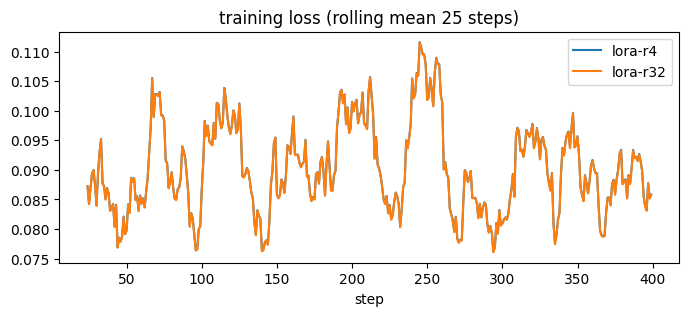

In [6]:
# Kaggle ships an old torchao that new peft rejects; we never use torchao, so switch its checks off
import peft, peft.tuners.lora.model, peft.import_utils
try:
    import peft.tuners.lora.torchao
except Exception:
    pass
def _no_torchao():
    for _n, _m in list(sys.modules.items()):
        if _m is not None and _n.startswith(("peft", "diffusers", "transformers")):
            if hasattr(_m, "is_torchao_available"): _m.is_torchao_available = lambda *a, **k: False
            if hasattr(_m, "dispatch_torchao"): _m.dispatch_torchao = lambda *a, **k: None
_no_torchao()
from diffusers import AutoencoderKL, UNet2DConditionModel, DDPMScheduler, StableDiffusionPipeline, DPMSolverMultistepScheduler
from diffusers.optimization import get_scheduler
from diffusers.training_utils import cast_training_params
from diffusers.utils import convert_state_dict_to_diffusers
from transformers import CLIPTextModel, CLIPTokenizer
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict
_no_torchao()
TDT = {("dtype" if int(transformers.__version__.split(".")[0]) >= 5 else "torch_dtype"): torch.float16}

# Pre-compute VAE latents and caption embeddings once (shared by both runs)
t0 = time.time()
tok = CLIPTokenizer.from_pretrained(BASE, subfolder="tokenizer")
te = CLIPTextModel.from_pretrained(BASE, subfolder="text_encoder", **TDT).to(DEVICE).eval()
vae = AutoencoderKL.from_pretrained(BASE, subfolder="vae").to(DEVICE).eval()          # fp32 VAE (fp16 SD1.5 VAE can give NaNs)
vae.enable_slicing()                                                                 # encode one image at a time inside a batch
ENC_BS = 4
captions = [r["text"] for r in train]
LAT, ENC = [], []
with torch.no_grad():
    for i in range(0, len(train512), ENC_BS):
        px = torch.stack([torch.from_numpy(np.asarray(im, dtype=np.float32) / 127.5 - 1).permute(2, 0, 1) for im in train512[i:i + ENC_BS]]).to(DEVICE)
        LAT.append((vae.encode(px).latent_dist.sample(generator=torch.Generator(DEVICE).manual_seed(SEED + i)) * vae.config.scaling_factor).half().cpu())
        ids = tok(captions[i:i + ENC_BS], padding="max_length", max_length=tok.model_max_length, truncation=True, return_tensors="pt").input_ids.to(DEVICE)
        ENC.append(te(ids)[0].half().cpu())
LAT, ENC = torch.cat(LAT), torch.cat(ENC)
del te, vae, train512; gc.collect(); torch.cuda.empty_cache()
print(f"pre-computed {len(LAT)} latents {tuple(LAT.shape[1:])} and caption embeddings in {time.time()-t0:.0f}s")

def train_run(run):
    torch.manual_seed(SEED); random.seed(SEED); np.random.seed(SEED)
    unet = UNet2DConditionModel.from_pretrained(BASE, subfolder="unet", torch_dtype=torch.float16).to(DEVICE)
    sched = DDPMScheduler.from_pretrained(BASE, subfolder="scheduler")
    unet.requires_grad_(False)
    _no_torchao()
    unet.add_adapter(LoraConfig(r=run["rank"], lora_alpha=run["rank"], init_lora_weights="gaussian",
                                target_modules=["to_k", "to_q", "to_v", "to_out.0"]))
    cast_training_params(unet, dtype=torch.float32)          # trainable LoRA weights in fp32, frozen UNet in fp16
    params = [p for p in unet.parameters() if p.requires_grad]
    n_train, n_total = sum(p.numel() for p in params), sum(p.numel() for p in unet.parameters())
    opt = torch.optim.AdamW(params, lr=LR, weight_decay=1e-2)
    lr_s = get_scheduler("cosine", optimizer=opt, num_warmup_steps=25, num_training_steps=STEPS)
    scaler = torch.amp.GradScaler("cuda")
    g = torch.Generator().manual_seed(SEED)                  # identical data order for both runs
    torch.cuda.reset_peak_memory_stats(); t0 = time.time(); losses, gc_on = [], False
    unet.train()
    step = 0
    while step < STEPS:
        idx = torch.randint(0, len(LAT), (BATCH,), generator=g)
        lat, enc = LAT[idx].to(DEVICE).float(), ENC[idx].to(DEVICE)
        noise = torch.randn_like(lat)
        ts = torch.randint(0, sched.config.num_train_timesteps, (BATCH,), device=DEVICE).long()
        noisy = sched.add_noise(lat, noise, ts)
        try:
            with torch.autocast("cuda", dtype=torch.float16):
                pred = unet(noisy.half(), ts, enc).sample
            loss = F.mse_loss(pred.float(), noise.float())
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
        except torch.cuda.OutOfMemoryError:
            if gc_on: raise
            print("out of memory without gradient checkpointing -> enabling it"); gc_on = True
            pred = loss = None; opt.zero_grad(set_to_none=True); gc.collect(); torch.cuda.empty_cache()
            unet.enable_gradient_checkpointing(); continue
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, 1.0)
        scaler.step(opt); scaler.update(); lr_s.step(); step += 1
        losses.append(loss.item())
        if step % 50 == 0:
            print(f"[{run['name']}] step {step}/{STEPS} loss {np.mean(losses[-50:]):.4f} {time.time()-t0:.0f}s")
    secs = time.time() - t0
    out = f"{WORK}/lora/{run['name']}"
    StableDiffusionPipeline.save_lora_weights(out, unet_lora_layers=convert_state_dict_to_diffusers(get_peft_model_state_dict(unet)),
                                              safe_serialization=True)
    stats = {"run": run["name"], "method": f"LoRA r={run['rank']}", "trainable params": n_train,
             "% of UNet": round(100 * n_train / n_total, 3), "learning rate": LR, "steps": STEPS,
             "batch size": BATCH * GRAD_ACC, "gradient checkpointing": gc_on,
             "peak GPU mem (GB)": round(torch.cuda.max_memory_allocated() / 1e9, 2),
             "train time (min)": round(secs / 60, 1), "GPU-hours": round(secs / 3600, 3),
             "final loss (avg last 50)": round(float(np.mean(losses[-50:])), 4)}
    json.dump({"stats": stats, "losses": losses}, open(f"{out}/train_log.json", "w"))
    del unet, opt; gc.collect(); torch.cuda.empty_cache()
    return stats, losses

TRAIN_STATS, LOSSES = [], {}
for run in RUNS:
    s_, l_ = train_run(run); TRAIN_STATS.append(s_); LOSSES[run["name"]] = l_
train_table = pd.DataFrame(TRAIN_STATS); display(train_table)
plt.figure(figsize=(8, 3))
for k, l in LOSSES.items(): plt.plot(pd.Series(l).rolling(25).mean(), label=k)
plt.legend(); plt.title("training loss (rolling mean 25 steps)"); plt.xlabel("step"); plt.savefig(f"{WORK}/grids/loss.png", dpi=100); plt.show()

In [7]:
# Push both adapters to Hugging Face (the model card of the final run is added after evaluation)
HF_REPOS = {}
if HF_TOKEN:
    for run in RUNS:
        rid = repo(run["name"])
        create_repo(rid, exist_ok=True, private=False, token=HF_TOKEN)
        api.upload_folder(folder_path=f"{WORK}/lora/{run['name']}", repo_id=rid, commit_message=f"{run['name']}: {STEPS} steps")
        HF_REPOS[run["name"]] = rid
print(HF_REPOS)

{'lora-r4': 'sayani0706/data266-lab2-team12-p2-lora-r4', 'lora-r32': 'sayani0706/data266-lab2-team12-p2-lora-r32'}


## 2.3 Image generation — 20 prompts × seeds {0,1} × {base, run 1, run 2} (DPM-Solver, 30 steps, CFG 7.5)

In [8]:
import threading
def new_pipe(lora_dir=None):
    """Fresh pipeline per model (swapping LoRAs in one pipeline froze once on Kaggle). NSFW safety checker stays on."""
    _no_torchao()
    p = StableDiffusionPipeline.from_pretrained(BASE, torch_dtype=torch.float16).to(DEVICE)
    p.scheduler = DPMSolverMultistepScheduler.from_config(p.scheduler.config); p.set_progress_bar_config(disable=True)
    if lora_dir: p.load_lora_weights(lora_dir)
    return p

rows = []
for m in MODELS:
    pipe = new_pipe(None if m == "base" else f"{WORK}/lora/{m}")
    os.makedirs(f"{WORK}/images/{m}", exist_ok=True); t0 = time.time()
    for p in PROMPTS:
        out = pipe(p["prompt"], num_images_per_prompt=2,
                   generator=[torch.Generator(DEVICE).manual_seed(0), torch.Generator(DEVICE).manual_seed(1)], **GEN)
        flags = out.nsfw_content_detected or [False, False]
        for seed, im, fl in zip((0, 1), out.images, flags):
            f = f"{WORK}/images/{m}/{p['id']}_s{seed}.png"; im.save(f)
            rows.append({"model": m, "prompt_id": p["id"], "type": p["type"], "prompt": p["prompt"], "seed": seed, "file": f,
                         "nsfw_flag": bool(fl), "steps": GEN["num_inference_steps"], "guidance": GEN["guidance_scale"], "sampler": "DPMSolverMultistep"})
        print(f"{m} {p['id']} done ({time.time()-t0:.0f}s)", flush=True)
    print(f"{m}: 40 images in {time.time()-t0:.0f}s", flush=True)
    del pipe; gc.collect(); torch.cuda.empty_cache()
meta = pd.DataFrame(rows)
print("NSFW-flagged outputs per model:", meta.groupby("model").nsfw_flag.sum().to_dict())
meta.to_csv(f"{WORK}/images/metadata.csv", index=False)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

... (8 outputs left out)

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


lora-r32 in00 done (10s)
lora-r32 in01 done (20s)
lora-r32 in02 done (31s)
lora-r32 in03 done (41s)
lora-r32 in04 done (51s)
lora-r32 in05 done (61s)
lora-r32 in06 done (71s)
lora-r32 in07 done (81s)
lora-r32 in08 done (91s)
lora-r32 in09 done (101s)
lora-r32 ood00 done (112s)
lora-r32 ood01 done (122s)
lora-r32 ood02 done (132s)
lora-r32 ood03 done (142s)
lora-r32 ood04 done (152s)
lora-r32 cmp00 done (162s)
lora-r32 cmp01 done (172s)
lora-r32 cmp02 done (182s)
lora-r32 cmp03 done (192s)
lora-r32 cmp04 done (203s)
lora-r32: 40 images in 203s
NSFW-flagged outputs per model: {'base': 0, 'lora-r32': 0, 'lora-r4': 0}


In [9]:
# Upload the 120 images (+ metadata) to a Hugging Face dataset, with a time limit so a slow upload cannot block the run
def _push():
    from datasets import Dataset, Image as HFImage
    Dataset.from_pandas(meta.rename(columns={"file": "image"})).cast_column("image", HFImage()).push_to_hub(repo("images"), token=HF_TOKEN)
    print("images uploaded to", repo("images"), flush=True)
if HF_TOKEN:
    th = threading.Thread(target=_push, daemon=True); th.start(); th.join(timeout=600)
    if th.is_alive(): print("image upload still running after 10 min - continuing; upload outputs/images later if needed")

Setting num_proc from 1 back to 1 for the train split to disable multiprocessing as it only contains one shard.


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Map:   0%|          | 0/120 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Validating:           |   0%            

images uploaded to sayani0706/data266-lab2-team12-p2-images


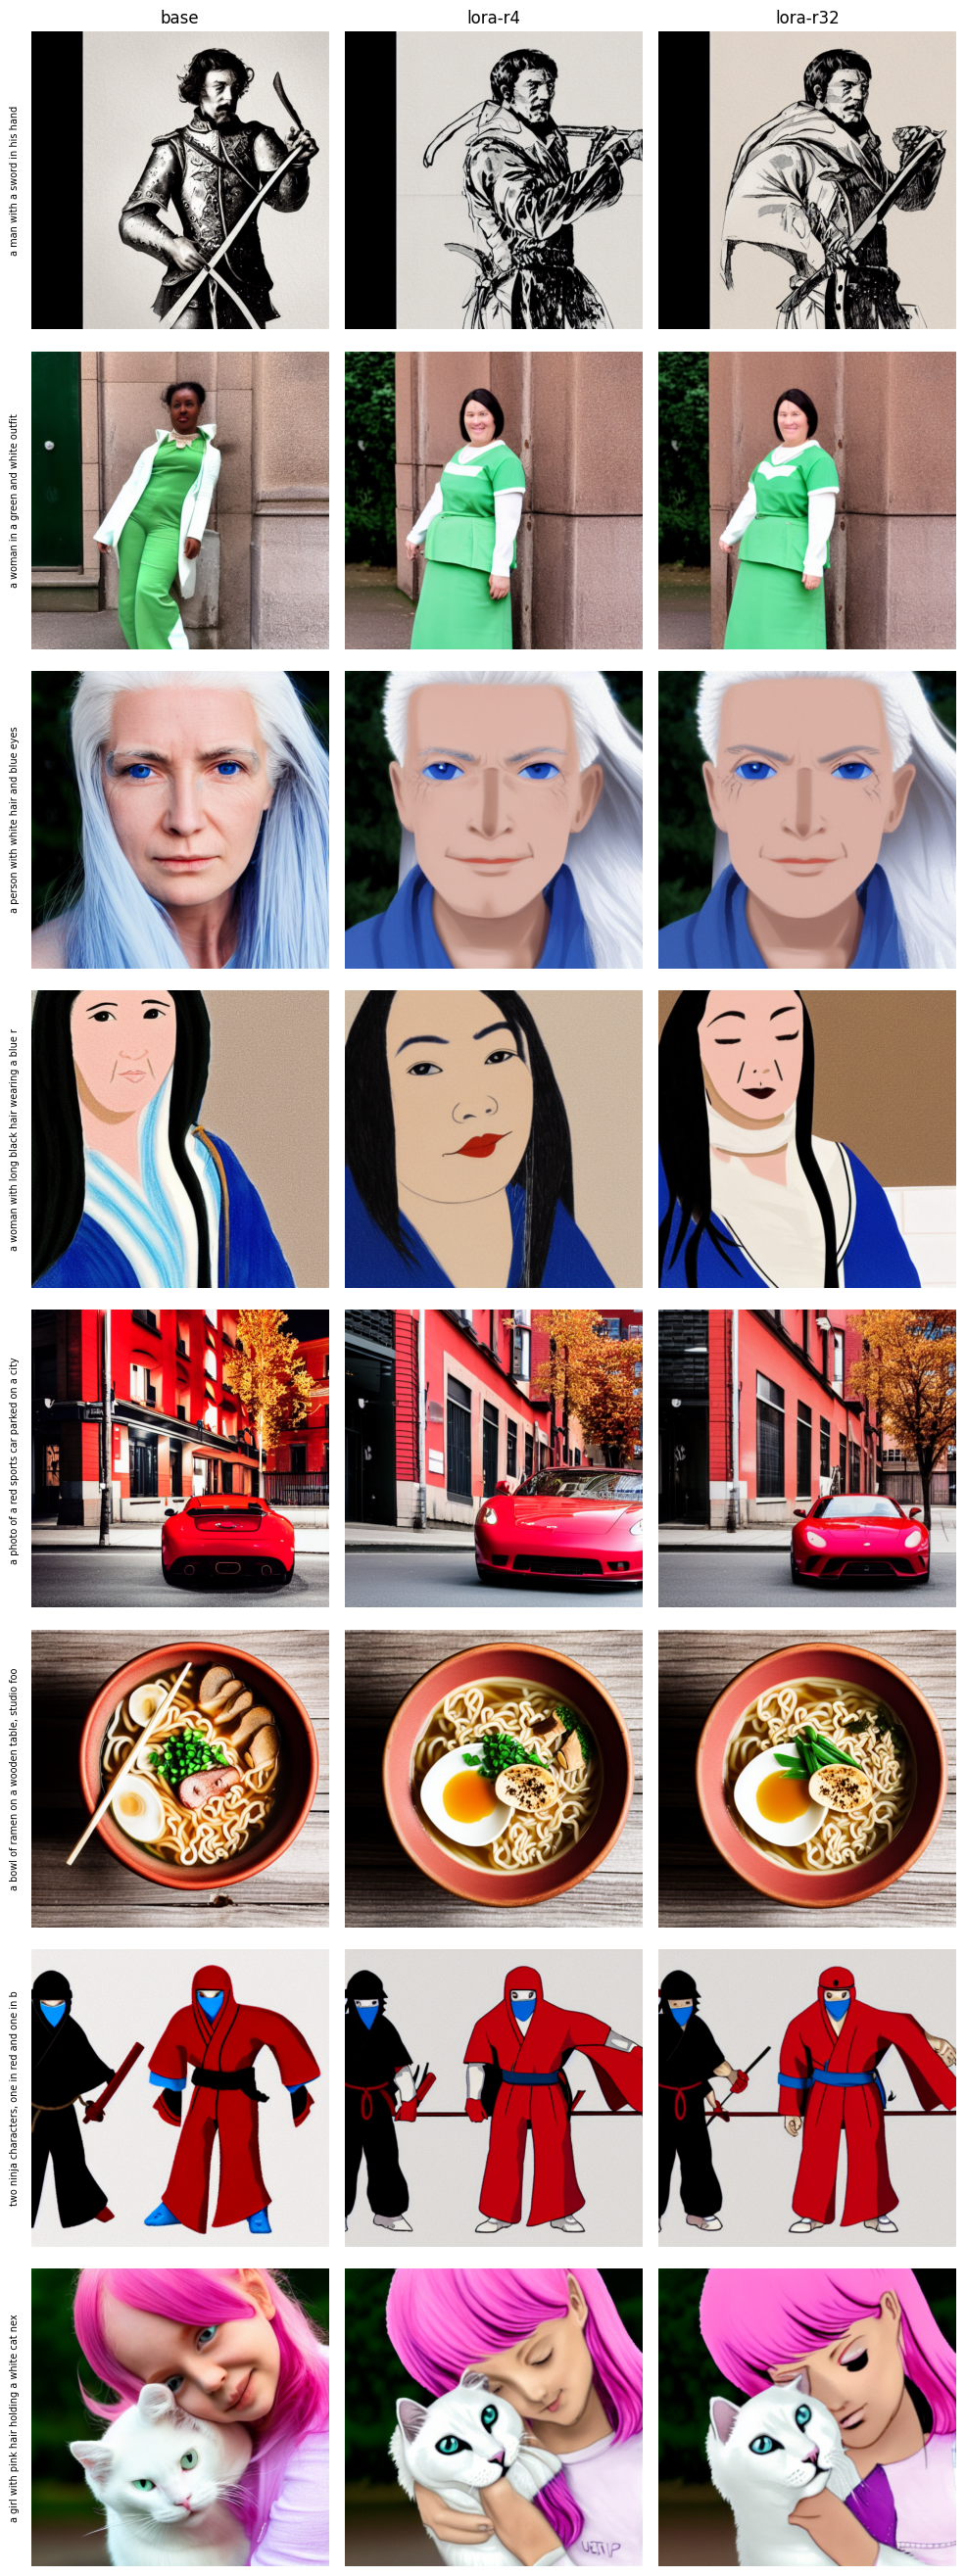

In [10]:
grid_ids = [p["id"] for p in PROMPTS if p["type"] == "in_domain"][:4] + [p["id"] for p in PROMPTS if p["type"] == "out_of_domain"][:2] + \
           [p["id"] for p in PROMPTS if p["type"] == "compositional"][:2]
fig, axes = plt.subplots(len(grid_ids), 3, figsize=(10, 3.3 * len(grid_ids)))
for r, pid in enumerate(grid_ids):
    for c, m in enumerate(MODELS):
        axes[r, c].imshow(Image.open(f"{WORK}/images/{m}/{pid}_s0.png")); axes[r, c].axis("off")
        if r == 0: axes[r, c].set_title(m, fontsize=12)
    axes[r, 0].text(-20, 256, next(p["prompt"] for p in PROMPTS if p["id"] == pid)[:45], rotation=90, va="center", ha="right", fontsize=7)
plt.tight_layout(); plt.savefig(f"{WORK}/grids/side_by_side.png", dpi=100); plt.show()

## 2.4 Evaluation — KID (in-domain vs test), CLIP score, LPIPS diversity, efficiency

In [11]:
from transformers import CLIPModel, CLIPProcessor
CLIP_ID = "openai/clip-vit-base-patch16"
cm = CLIPModel.from_pretrained(CLIP_ID).to(DEVICE).eval(); cp = CLIPProcessor.from_pretrained(CLIP_ID)

@torch.no_grad()
def clip_img(pils, bs=32):
    out = []
    for i in range(0, len(pils), bs):
        x = cp(images=[p.convert("RGB") for p in pils[i:i+bs]], return_tensors="pt")["pixel_values"].to(DEVICE)
        out.append(F.normalize(cm.visual_projection(cm.vision_model(pixel_values=x).pooler_output), dim=-1))
    return torch.cat(out)

@torch.no_grad()
def clip_txt(texts):
    t = cp(text=list(texts), return_tensors="pt", padding=True, truncation=True, max_length=77).to(DEVICE)
    return F.normalize(cm.text_projection(cm.text_model(input_ids=t["input_ids"], attention_mask=t["attention_mask"]).pooler_output), dim=-1)

def u8(pil): return torch.from_numpy(np.asarray(pil.convert("RGB"))).permute(2, 0, 1)

RESULTS = {m: {"model": m} for m in MODELS}

@step("CLIP score (100 * cosine, as in torchmetrics CLIPScore)")
def _():
    e_i = clip_img([Image.open(f) for f in meta.file]); e_t = clip_txt(meta.prompt)
    meta["clip_score"] = (100 * (e_i * e_t).sum(-1).clamp(min=0)).cpu().numpy()
    for m in MODELS:
        s = meta[meta.model == m]
        RESULTS[m]["CLIP score (all 40)"] = round(s["clip_score"].mean(), 2)
        for t in ("in_domain", "out_of_domain", "compositional"):
            RESULTS[m][f"CLIP {t}"] = round(s[s.type == t]["clip_score"].mean(), 2)

@step("KID (in-domain generations vs 122 test images)")
def _():
    from torchmetrics.image.kid import KernelInceptionDistance
    real = torch.stack([u8(r["image"]) for r in test])
    for m in MODELS:
        ind = meta[(meta.model == m) & (meta.type == "in_domain")]
        kid = KernelInceptionDistance(subset_size=min(10, len(ind)), subsets=100).to(DEVICE)
        torch.manual_seed(SEED)
        kid.update(real.to(DEVICE), real=True); kid.update(torch.stack([u8(Image.open(f)) for f in ind.file]).to(DEVICE), real=False)
        mu, sd = kid.compute(); RESULTS[m]["KID in-domain (mean)"] = round(mu.item(), 4); RESULTS[m]["KID std"] = round(sd.item(), 4)

@step("LPIPS diversity (seed 0 vs seed 1, same prompt)")
def _():
    try:
        from torchmetrics.image.lpip import LearnedPerceptualImagePatchSimilarity
        lp = LearnedPerceptualImagePatchSimilarity(net_type="alex", normalize=True).to(DEVICE)
        dist = lambda a, b: lp(a, b).item()
    except Exception:
        import lpips; _l = lpips.LPIPS(net="alex").to(DEVICE); dist = lambda a, b: _l(a * 2 - 1, b * 2 - 1).item()
    pairs = {}
    for (m, pid), g in meta.groupby(["model", "prompt_id"]):
        a, b = [(u8(Image.open(f)).float() / 255).unsqueeze(0).to(DEVICE) for f in g.sort_values("seed").file]
        pairs[(m, pid)] = dist(a, b)
    meta["lpips_pair"] = [pairs[(m, p)] for m, p in zip(meta.model, meta.prompt_id)]
    for m in MODELS: RESULTS[m]["LPIPS diversity"] = round(float(np.mean([v for (mm, _), v in pairs.items() if mm == m])), 4)

for s in TRAIN_STATS:
    RESULTS[s["run"]].update({"trainable params": s["trainable params"], "% of UNet": s["% of UNet"], "train time (min)": s["train time (min)"],
                              "GPU-hours": s["GPU-hours"], "peak GPU mem (GB)": s["peak GPU mem (GB)"]})
RES_DF = pd.DataFrame(list(RESULTS.values())); display(RES_DF); RES_DF.to_csv(f"{WORK}/p2_results.csv", index=False)
meta.to_csv(f"{WORK}/images/metadata.csv", index=False)

config.json:   0%|          | 0.00/4.10k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

model.safetensors: downloading bytes:           |  0.00B            

... (8 outputs left out)

[ok] KID (in-domain generations vs 122 test images) (4s)
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 207MB/s]  


[ok] LPIPS diversity (seed 0 vs seed 1, same prompt) (4s)


,model,CLIP score (all 40),CLIP in_domain,CLIP out_of_domain,CLIP compositional,KID in-domain (mean),KID std,LPIPS diversity,trainable params,% of UNet,train time (min),GPU-hours,peak GPU mem (GB)
0,base,32.52,30.990000,31.730000,36.389999,0.1049,0.0212,0.8094,NaN,NaN,NaN,NaN,NaN
1,lora-r4,31.85,30.110001,31.129999,36.040001,0.0613,0.0185,0.8126,797184.0,0.093,6.0,0.1,6.44
2,lora-r32,31.67,30.090000,31.250000,35.259998,0.0531,0.0167,0.8083,6377472.0,0.737,6.0,0.1,6.57


In [12]:
# Final run = lower KID (closer to the domain); falls back to higher in-domain CLIP if KID is unavailable
runs_df = RES_DF[RES_DF.model != "base"]
if "KID in-domain (mean)" in runs_df: FINAL = runs_df.sort_values("KID in-domain (mean)").iloc[0]["model"]
elif "CLIP in_domain" in runs_df: FINAL = runs_df.sort_values("CLIP in_domain", ascending=False).iloc[0]["model"]
else: FINAL = "lora-r32"
FINAL = os.environ.get("FINAL_RUN", FINAL)
print("final run:", FINAL)

final run: lora-r32


### Human evaluation — 25 blinded pairs (final run vs base, left/right randomised), ≥ 3 raters

In [13]:
rng = np.random.RandomState(SEED)
cands = [(p["id"], s) for p in PROMPTS for s in (0, 1)]
key = []
for k, i in enumerate(rng.choice(len(cands), 25, replace=False)):
    pid, s = cands[i]; left_final = bool(rng.rand() < 0.5)
    L, R = (FINAL, "base") if left_final else ("base", FINAL)
    canvas = Image.new("RGB", (RES * 2 + 20, RES), "white")
    canvas.paste(Image.open(f"{WORK}/images/{L}/{pid}_s{s}.png"), (0, 0)); canvas.paste(Image.open(f"{WORK}/images/{R}/{pid}_s{s}.png"), (RES + 20, 0))
    canvas.save(f"{WORK}/human_eval/pair_{k:02d}.png")
    key.append({"pair_id": k, "prompt": next(p["prompt"] for p in PROMPTS if p["id"] == pid), "left_is_final": left_final})
pd.DataFrame(key).to_csv(f"{WORK}/human_eval/key_DO_NOT_SHOW_RATERS.csv", index=False)
pd.DataFrame([{"pair_id": k["pair_id"], "prompt": k["prompt"], "rater": "", "domain_style (L/R)": "", "prompt_match (L/R)": ""} for k in key]) \
  .to_csv(f"{WORK}/human_eval/rating_sheet.csv", index=False)
print("Give each rater human_eval/pair_XX.png + rating_sheet.csv; merge the filled sheets into eval/p2_human_ratings.csv")
HR = next((p for p in ["eval/p2_human_ratings.csv", "../eval/p2_human_ratings.csv", *glob.glob("/kaggle/input/**/p2_human_ratings.csv", recursive=True)] if os.path.exists(p)), None)
if HR:
    hr = pd.read_csv(HR).merge(pd.DataFrame(key)[["pair_id", "left_is_final"]], on="pair_id")
    for c in ["domain_style (L/R)", "prompt_match (L/R)"]:
        hr[c + " final wins"] = (hr[c].astype(str).str.upper().str.strip() == "L") == hr.left_is_final
    print("raters:", hr.rater.nunique()); display(hr.groupby("rater")[[c for c in hr if c.endswith("final wins")]].mean().round(2))
    print("win rate of final vs base:", hr[[c for c in hr if c.endswith("final wins")]].mean().round(3).to_dict())

Give each rater human_eval/pair_XX.png + rating_sheet.csv; merge the filled sheets into eval/p2_human_ratings.csv


### Failure modes

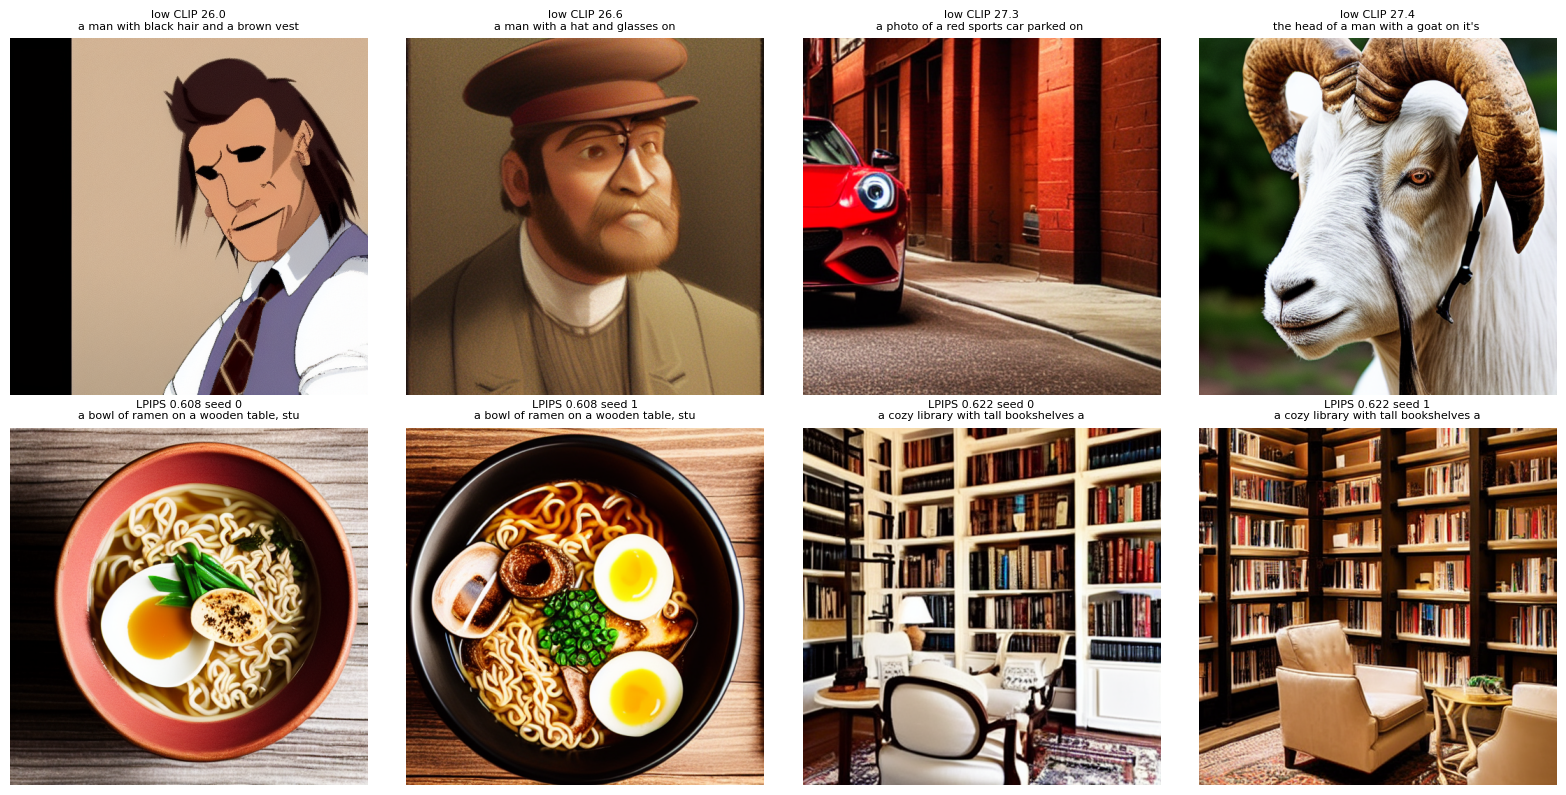

[ok] failure-mode figure (2s)


In [14]:
@step("failure-mode figure")
def _():
    fin = meta[meta.model == FINAL]
    worst = fin.sort_values("clip_score").head(4); low = fin.sort_values("lpips_pair").drop_duplicates("prompt_id").head(2)
    fig, ax = plt.subplots(2, 4, figsize=(16, 8))
    for a, (_, r) in zip(ax[0], worst.iterrows()):
        a.imshow(Image.open(r.file)); a.set_title(f"low CLIP {r['clip_score']:.1f}\n{r.prompt[:38]}", fontsize=8); a.axis("off")
    for j, (_, r) in enumerate(low.iterrows()):
        for s in (0, 1):
            a = ax[1, 2 * j + s]; a.imshow(Image.open(f"{WORK}/images/{FINAL}/{r.prompt_id}_s{s}.png")); a.axis("off")
            a.set_title(f"LPIPS {r.lpips_pair:.3f} seed {s}\n{r.prompt[:38]}", fontsize=8)
    plt.tight_layout(); plt.savefig(f"{WORK}/grids/failure_modes.png", dpi=100); plt.show()

## Safety (C4): memorisation — nearest training image for 10 in-domain generations (CLIP image similarity)

,generated,nearest_train_idx,clip_sim
5,/kaggle/working/images/lora-r32/in05_s0.png,814,0.8654
2,/kaggle/working/images/lora-r32/in02_s0.png,430,0.8518
3,/kaggle/working/images/lora-r32/in03_s0.png,1055,0.7504
0,/kaggle/working/images/lora-r32/in00_s0.png,66,0.7213
9,/kaggle/working/images/lora-r32/in09_s0.png,507,0.7036
7,/kaggle/working/images/lora-r32/in07_s0.png,1055,0.6955
4,/kaggle/working/images/lora-r32/in04_s0.png,843,0.6771
8,/kaggle/working/images/lora-r32/in08_s0.png,833,0.6680
6,/kaggle/working/images/lora-r32/in06_s0.png,124,0.6053
1,/kaggle/working/images/lora-r32/in01_s0.png,567,0.5394


max similarity: 0.8654000163078308 (>= ~0.95 would suggest a near-copy)


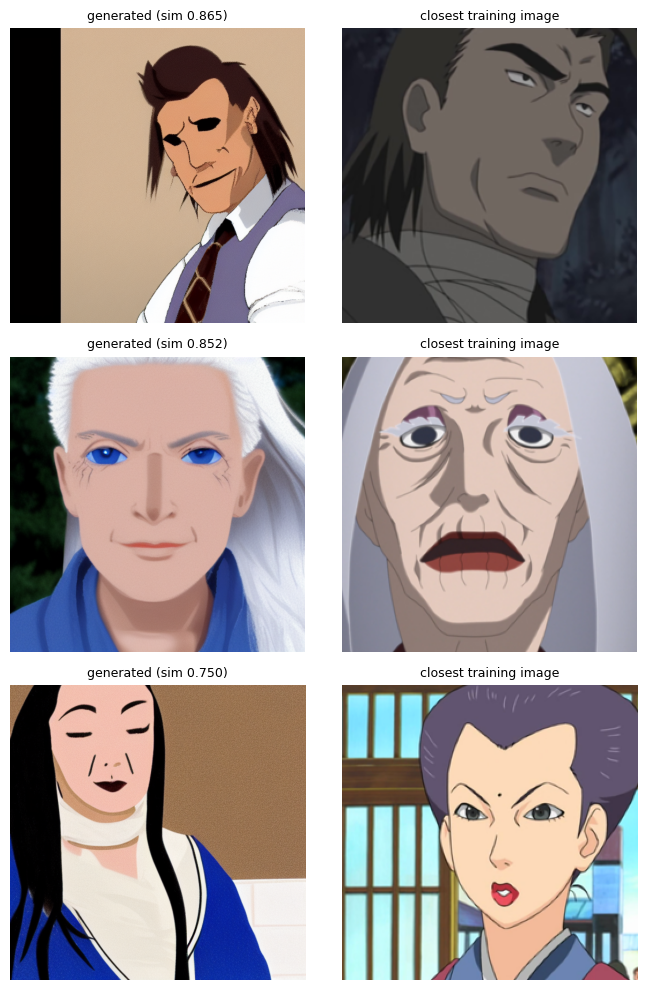

[ok] memorisation check (14s)


In [15]:
@step("memorisation check")
def _():
    gen = meta[(meta.model == FINAL) & (meta.type == "in_domain") & (meta.seed == 0)].file.tolist()[:10]
    sims = clip_img([Image.open(f) for f in gen]) @ clip_img([r["image"] for r in train]).T
    best, idx = sims.max(1)
    mem = pd.DataFrame({"generated": gen, "nearest_train_idx": idx.tolist(), "clip_sim": best.cpu().numpy().round(4)}).sort_values("clip_sim", ascending=False)
    display(mem); print("max similarity:", mem.clip_sim.max(), "(>= ~0.95 would suggest a near-copy)")
    fig, ax = plt.subplots(3, 2, figsize=(7, 10))
    for r, (_, row) in enumerate(mem.head(3).iterrows()):
        ax[r, 0].imshow(Image.open(row.generated)); ax[r, 0].set_title(f"generated (sim {row.clip_sim:.3f})", fontsize=9)
        ax[r, 1].imshow(train[row.nearest_train_idx]["image"]); ax[r, 1].set_title("closest training image", fontsize=9)
        for a in ax[r]: a.axis("off")
    plt.tight_layout(); plt.savefig(f"{WORK}/grids/memorization_top3.png", dpi=100); plt.show()
    mem.to_csv(f"{WORK}/memorization.csv", index=False)

### Model card for the final run

In [16]:
@step("model card")
def _():
    ts = next(s for s in TRAIN_STATS if s["run"] == FINAL); rr = RES_DF.set_index("model")
    g = lambda m, c: rr.loc[m, c] if c in rr.columns else "n/a"
    card = f"""---
license: creativeml-openrail-m
base_model: {BASE}
datasets: [{DATASET}]
tags: [stable-diffusion, lora, text-to-image, diffusers, data266]
---
# DATA 266 Lab 2 Team {TEAM} — {FINAL} (Stable Diffusion 1.5 LoRA, Naruto style)
**Base model:** {BASE} at {RES}x{RES}. **Data:** {DATASET}: {len(kept)} images kept ({n_corrupt} corrupted, {n_exact + n_near} duplicates removed); 90/10 split, seed {SEED} ({len(train)} train / {len(test)} test).
**Training:** {ts['method']} on UNet attention (to_q/k/v/out), {ts['trainable params']:,} trainable parameters ({ts['% of UNet']}% of UNet), lr {LR} cosine (25 warm-up), {STEPS} steps, batch {BATCH*GRAD_ACC}, fp16 mixed precision with pre-computed VAE latents, 1x Tesla T4, {ts['GPU-hours']} GPU-h, peak {ts['peak GPU mem (GB)']} GB.
**Results (20 prompts x 2 seeds, DPM-Solver 30 steps, CFG 7.5):** KID in-domain vs test {g(FINAL,'KID in-domain (mean)')} (base {g('base','KID in-domain (mean)')}); CLIP score {g(FINAL,'CLIP score (all 40)')} (base {g('base','CLIP score (all 40)')}); LPIPS diversity {g(FINAL,'LPIPS diversity')} (base {g('base','LPIPS diversity')}).
**Limitations:** generic BLIP captions (e.g. "a man with ...") give weak text control; out-of-domain prompts drift to the anime style; KID with 20 images is noisy.
**License / intended use:** Naruto characters are copyrighted - non-commercial research and education only. Generation keeps the SD safety checker (NSFW filter) on.
**Usage:** `pipe.load_lora_weights("{HF_REPOS.get(FINAL, repo(FINAL))}")`
"""
    open(f"{WORK}/lora/{FINAL}/README.md", "w").write(card); print(card)
    if HF_TOKEN:
        api.upload_file(path_or_fileobj=f"{WORK}/lora/{FINAL}/README.md", path_in_repo="README.md", repo_id=HF_REPOS.get(FINAL, repo(FINAL)))

---
license: creativeml-openrail-m
base_model: stable-diffusion-v1-5/stable-diffusion-v1-5
datasets: [lambdalabs/naruto-blip-captions]
tags: [stable-diffusion, lora, text-to-image, diffusers, data266]
---
# DATA 266 Lab 2 Team 12 — lora-r32 (Stable Diffusion 1.5 LoRA, Naruto style)
**Base model:** stable-diffusion-v1-5/stable-diffusion-v1-5 at 512x512. **Data:** lambdalabs/naruto-blip-captions: 1221 images kept (0 corrupted, 0 duplicates removed); 90/10 split, seed 266 (1099 train / 122 test).
**Training:** LoRA r=32 on UNet attention (to_q/k/v/out), 6,377,472 trainable parameters (0.737% of UNet), lr 0.0001 cosine (25 warm-up), 400 steps, batch 4, fp16 mixed precision with pre-computed VAE latents, 1x Tesla T4, 0.1 GPU-h, peak 6.57 GB.
**Results (20 prompts x 2 seeds, DPM-Solver 30 steps, CFG 7.5):** KID in-domain vs test 0.0531 (base 0.1049); CLIP score 31.670000076293945 (base 32.52000045776367); LPIPS diversity 0.8083 (base 0.8094).
**Limitations:** generic BLIP captions (e.g. "a m

In [17]:
shutil.rmtree(f"{WORK}/lora/{RUNS[0]['name']}/.cache", ignore_errors=True); shutil.rmtree(f"{WORK}/lora/{RUNS[1]['name']}/.cache", ignore_errors=True)
print("done. HF:", HF_REPOS, "| images:", repo("images"))

done. HF: {'lora-r4': 'sayani0706/data266-lab2-team12-p2-lora-r4', 'lora-r32': 'sayani0706/data266-lab2-team12-p2-lora-r32'} | images: sayani0706/data266-lab2-team12-p2-images


In [19]:
import shutil, glob, os
from IPython.display import FileLink
print("inputs:", glob.glob("/kaggle/input/*") + glob.glob("/kaggle/input/*/*"))
hits = glob.glob("/kaggle/input/**/p2_results.csv", recursive=True) or glob.glob("/kaggle/input/**/human_eval", recursive=True)
src = os.path.dirname(hits[0]) if hits and hits[0].endswith(".csv") else (os.path.dirname(hits[0]) if hits else None)
print("found:", src)
shutil.make_archive("/kaggle/working/part2_outputs", "zip", src)
print(round(os.path.getsize("/kaggle/working/part2_outputs.zip") / 1e6, 1), "MB")
FileLink("part2_outputs.zip")

inputs: []
found: None
107.9 MB


/kaggle/working/part2_outputs.zip